In [2]:
import SimpleITK as sitk
import matplotlib.pyplot as plt
from pathlib import Path
import numpy as np


import sys
sys.path.insert(0, "/workspace/segmentation")
from tools import img_show3D, window, img_show2D


In [3]:
img_dir = Path ("/workspace/segmentation/data/practice/image_quadra/QUADRA_HC_021/retest_CT-AC.nii.gz")
img = sitk.ReadImage(img_dir)

img_window = window (img, window_width = 400, window_center = 40)

In [4]:
img_slice_win = img_window[80: 450,100 : 350, 265]
img_slice = img[80: 450,100 : 350, 265]

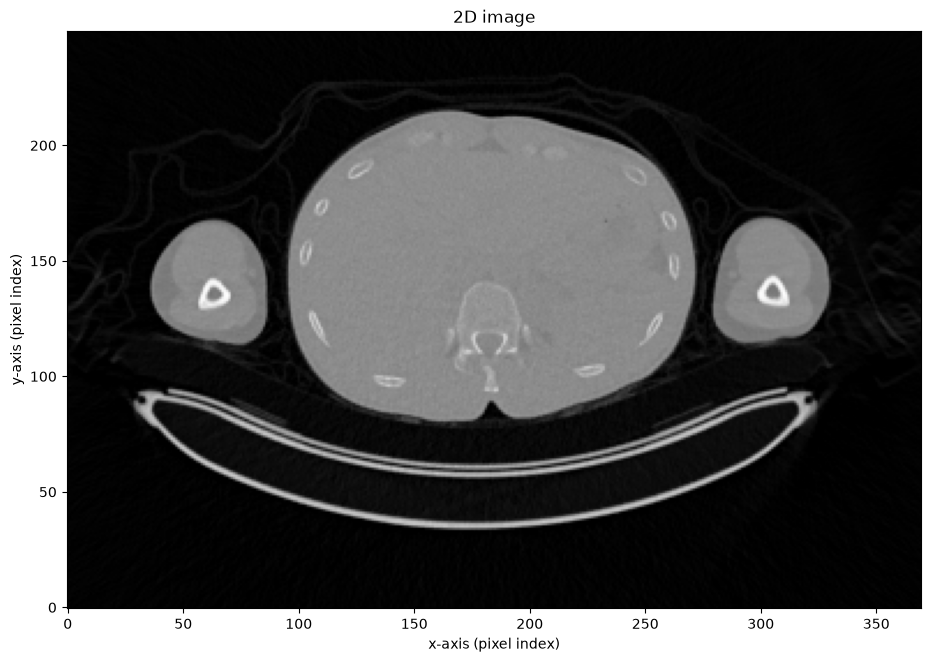

In [5]:
img_show2D (img_slice, scale = 3)

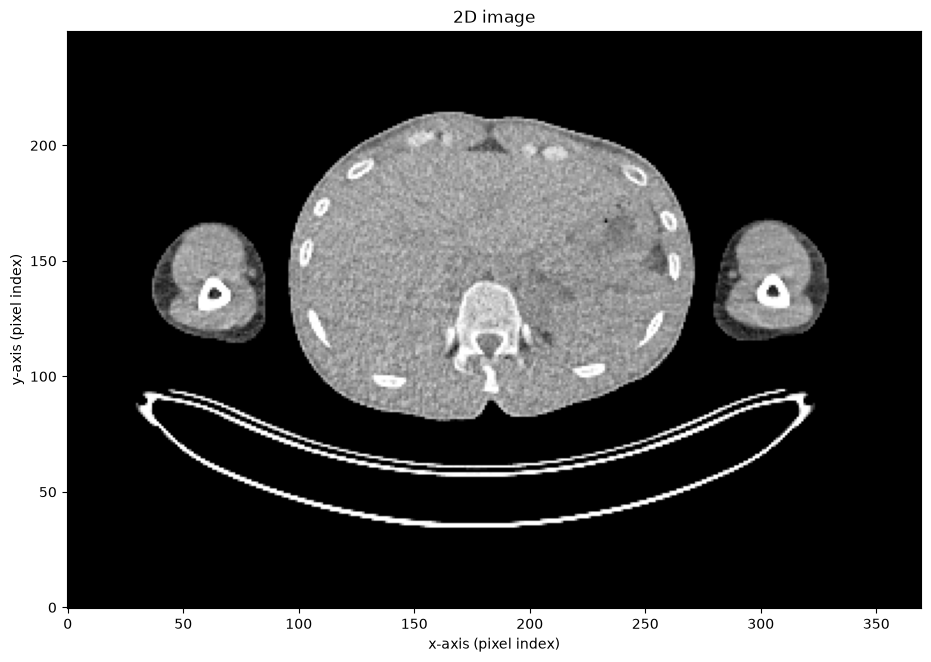

In [6]:
img_show2D(img_slice_win, scale = 3)

In [7]:
mask_dir = Path ("/workspace/segmentation/data/practice/mask_quadra/QUADRA_HC_021/retest/liver.nii.gz")
mask = sitk.ReadImage(mask_dir)

In [8]:
def crop_img_mask (img, mask):

    padding = 10

    stats = sitk.LabelShapeStatisticsImageFilter()
    stats.Execute(mask)
    x_start, y_start, z_start, x_size, y_size, z_size = stats.GetBoundingBox(1)
    x_end = x_start + x_size - 1
    y_end = y_start + y_size - 1
    z_end = z_start + z_size - 1

    img_cut = img[x_start - padding: x_end + padding, y_start - padding: y_end + padding, z_start - padding: z_end + padding]
    mask_cut = mask[x_start - padding: x_end + padding, y_start - padding: y_end + padding, z_start - padding: z_end + padding]

    return img_cut, mask_cut



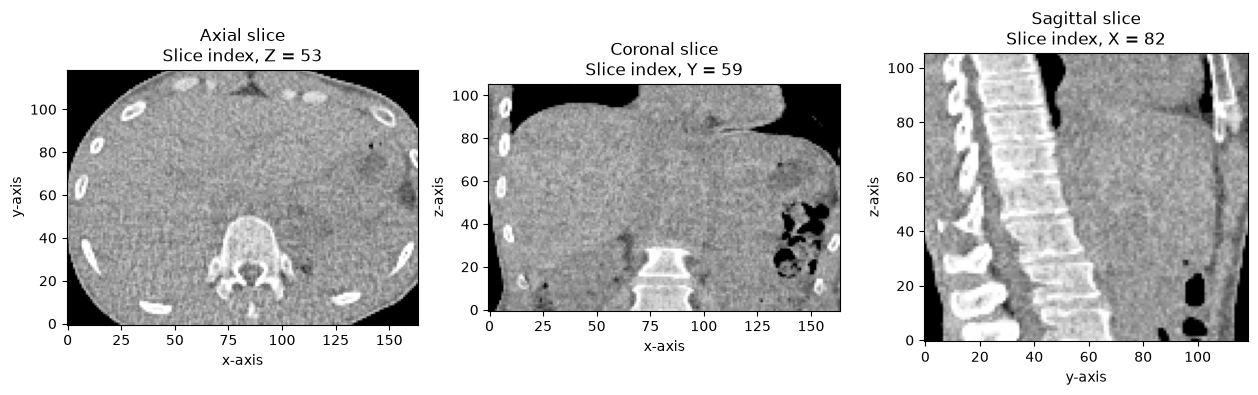

In [9]:
crop_img, crop_mask = crop_img_mask(img_window, mask)
img_show3D (crop_img, scale = 3)

In [10]:
img.GetSpacing()

(1.5234375, 1.5234375, 2.0)

In [18]:
sigma = 1.5

smooting_filter = sitk.SmoothingRecursiveGaussianImageFilter()
smooting_filter.SetSigma(sigma)

smooth_img = smooting_filter.Execute(img)

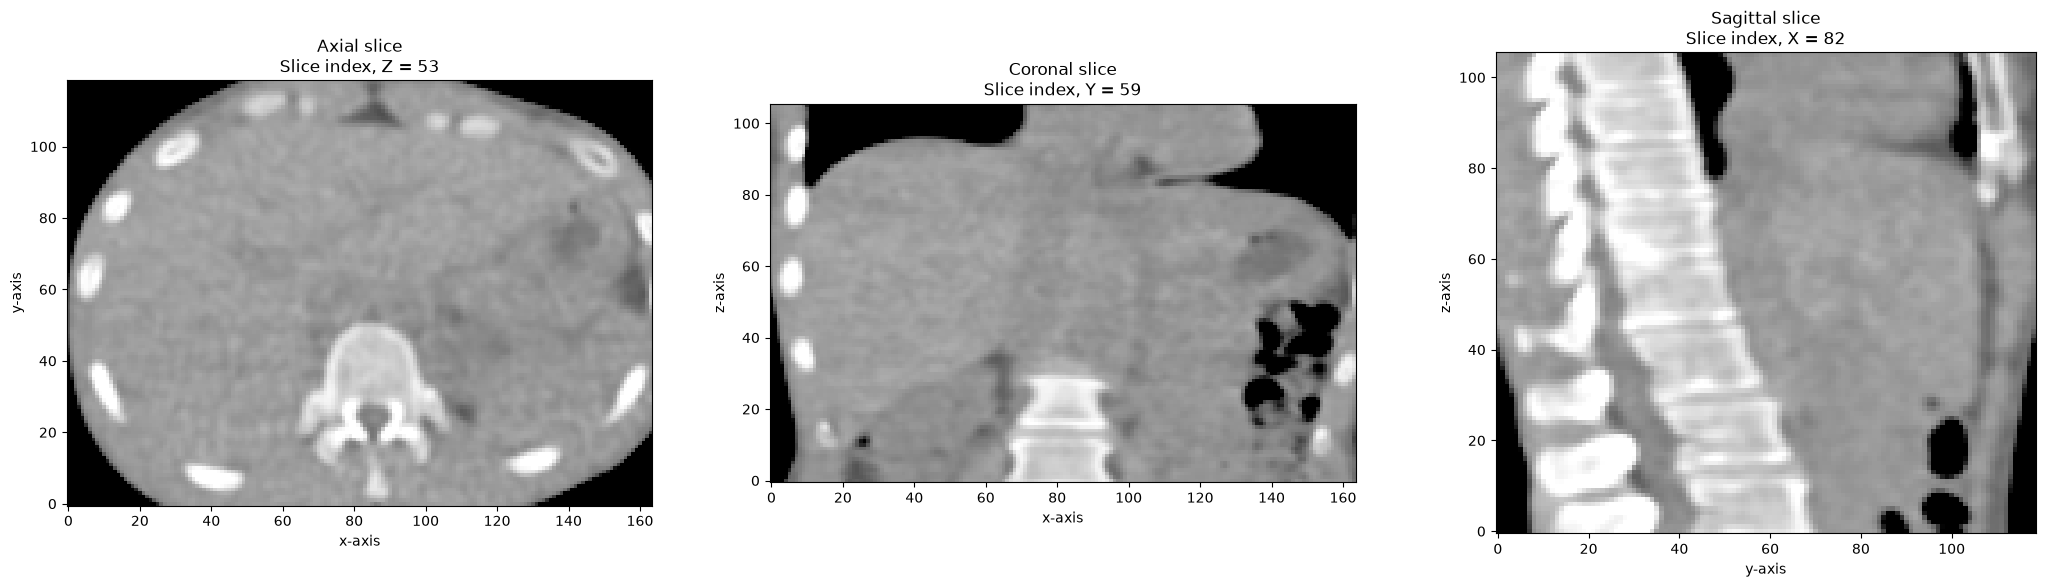

In [19]:
smooth_img_win = window (smooth_img, window_width = 400, window_center = 40)
crop_img_win, crop_mask = crop_img_mask(smooth_img_win, mask)
img_show3D (crop_img_win, scale = 5)

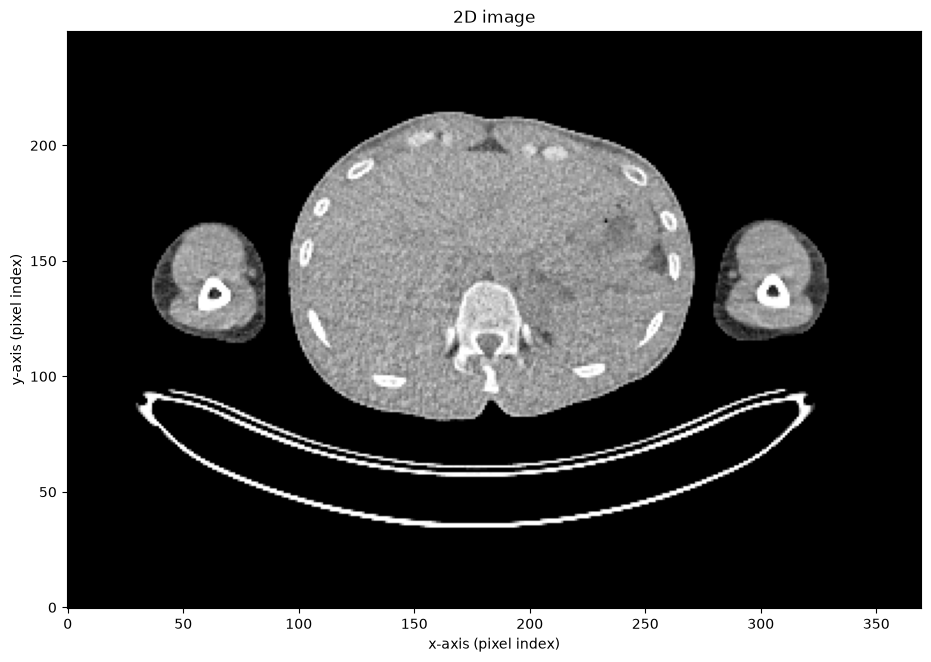

In [20]:
img_show2D(img_slice_win, scale = 3)

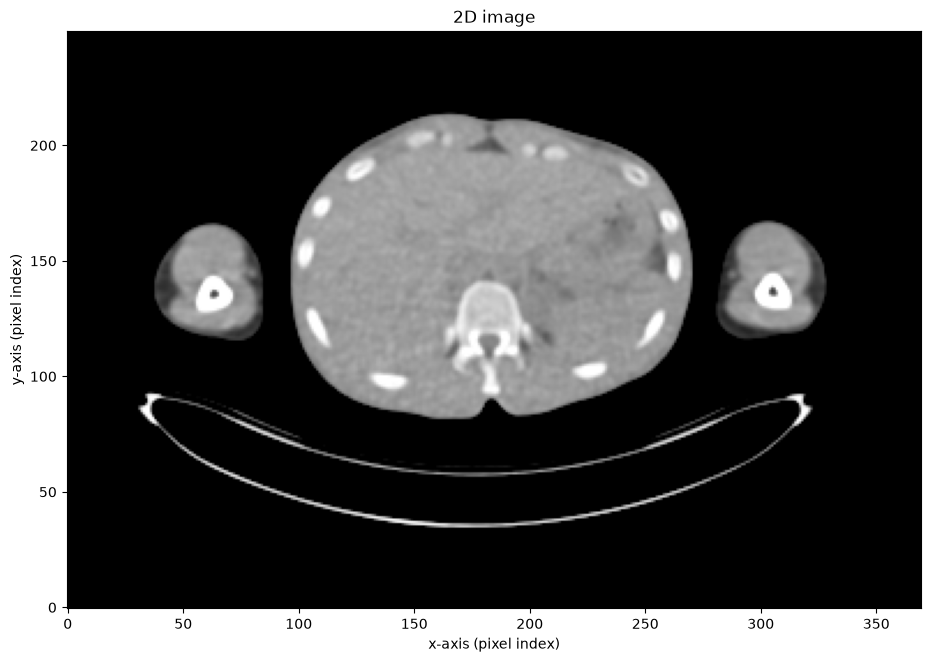

In [21]:
smooth_win_slice = smooth_img_win[80: 450,100 : 350, 265]
img_show2D(smooth_win_slice, scale = 3)

In [22]:
img[256, 256, 265]

48.0

In [23]:
smooth_img[256, 256, 265]

53.9743766784668